# Notebook 04 — PQC Migration Module

**Project:** RSA Hardness Prediction & PQC Migration Framework
**Phase 4:** Map predicted RSA vulnerability to NIST post-quantum migration guidance

**What this module does:**
1. Translates predicted factorization difficulty into NIST security levels
2. Computes migration urgency scores for each RSA key
3. Recommends appropriate PQC replacement schemes (Kyber, Dilithium)
4. Visualizes the RSA → PQC migration landscape

**Key reference:** NIST SP 800-57 Part 1 Rev. 5

**No training involved — this is deterministic policy mapping.**
**Estimated runtime:** < 1 minute

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from src.features import get_feature_names
from src.utils import (
    set_global_seed, print_section, log_memory, save_metadata,
)
from config import (
    SEED, DATA_PROC, DATA_META, PROJECT_ROOT,
    RESULTS_FIG, RESULTS_TAB,
    SMALL_PRIMES, POWER_MODS,
    NIST_RSA_SECURITY, PQC_LEVELS, URGENCY_WEIGHTS,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

# Output directories for PQC results
PQC_FIG = PROJECT_ROOT / "results" / "figures_pqc"
PQC_TAB = PROJECT_ROOT / "results" / "tables_pqc"
PQC_FIG.mkdir(parents=True, exist_ok=True)
PQC_TAB.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"PQC Figures:  {PQC_FIG}")
print(f"PQC Tables:   {PQC_TAB}")

Project root: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework
PQC Figures:  D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures_pqc
PQC Tables:   D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_pqc


## 1. Load Dataset & Predictions

Load the benchmarked dataset and the saved simplified models
to generate vulnerability predictions for every semiprime.

In [2]:
print_section("Loading Dataset & Models")

# Load dataset
df = pd.read_csv(DATA_PROC / "dataset_with_features_and_runtimes.csv")
df = df[df["best_algorithm"] != "none"].reset_index(drop=True)

feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)
available_features = [f for f in feature_names if f in df.columns]

for col in available_features:
    if df[col].dtype == "object":
        df[col] = pd.to_numeric(df[col], errors="coerce")

X_all = df[available_features].astype(np.float64)

# Load simplified models
SIMPLE_MODELS = PROJECT_ROOT / "models" / "simplified"

xgb_reg = joblib.load(SIMPLE_MODELS / "xgboost_regressor.pkl")
meta_reg = joblib.load(SIMPLE_MODELS / "elasticnet_meta.pkl")
xgb_cls = joblib.load(SIMPLE_MODELS / "xgb_classifier.pkl")
label_encoder = joblib.load(SIMPLE_MODELS / "label_encoder.pkl")

# Load CatBoost separately
from catboost import CatBoostRegressor
cb_reg = CatBoostRegressor()
cb_reg.load_model(str(SIMPLE_MODELS / "catboost_regressor.cbm"))

print(f"Dataset: {len(df):,} samples, {len(available_features)} features")
print(f"Models loaded from: {SIMPLE_MODELS}")

# Generate predictions for all samples
pred_xgb = xgb_reg.predict(X_all)
pred_cb = cb_reg.predict(X_all)
meta_X = np.column_stack([pred_xgb, pred_cb])
df["predicted_log_runtime"] = meta_reg.predict(meta_X)
df["predicted_algorithm"] = label_encoder.inverse_transform(xgb_cls.predict(X_all))

print(f"\nPredictions generated for all {len(df):,} samples")
print(f"Predicted runtime range: [{df['predicted_log_runtime'].min():.2f}, "
      f"{df['predicted_log_runtime'].max():.2f}]")
print(f"Predicted algorithm distribution:")
print(df["predicted_algorithm"].value_counts())

log_memory("after predictions")


══════════════════════════════════════════════════════════════════════
  Loading Dataset & Models
══════════════════════════════════════════════════════════════════════

Dataset: 9,367 samples, 39 features
Models loaded from: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\models\simplified

Predictions generated for all 9,367 samples
Predicted runtime range: [-15.59, -0.23]
Predicted algorithm distribution:
predicted_algorithm
pollard_rho    4601
ecm            4517
fermat          185
pollard_pm1      64
Name: count, dtype: int64
  [MEM] after predictions: 339.6 MB


## 2. NIST Security Level Mapping

Map each semiprime's bit-length to its NIST classical security level
using SP 800-57 Part 1 Rev. 5 equivalence tables.

| RSA Modulus (bits) | Classical Security (bits) | NIST Level | PQC Equivalent |
|-------------------|--------------------------|------------|----------------|
| 1024 | 80 (deprecated) | Below Level 1 | Immediate migration |
| 2048 | 112 | Level 1 | Kyber-512 / Dilithium-2 |
| 3072 | 128 | Level 1 | Kyber-512 / Dilithium-2 |
| 4096 | ~140 | Level 3 | Kyber-768 / Dilithium-3 |
| 7680 | 192 | Level 3 | Kyber-768 / Dilithium-3 |
| 15360 | 256 | Level 5 | Kyber-1024 / Dilithium-5 |

Since our dataset uses 32–160 bit semiprimes (research-scale, not production),
we extrapolate the NIST mapping to demonstrate the framework's methodology.

In [3]:
print_section("NIST Security Level Mapping")

print("NIST SP 800-57 RSA Security Equivalences:")
print(f"  {'RSA bits':>10} {'Security bits':>15} {'Status':<20}")
print(f"  {'-'*50}")
for rsa_bits, sec_bits in sorted(NIST_RSA_SECURITY.items()):
    status = "DEPRECATED" if sec_bits < 112 else "ACCEPTABLE" if sec_bits <= 128 else "STRONG"
    print(f"  {rsa_bits:>10} {sec_bits:>15} {status:<20}")

print(f"\nPQC Replacement Levels:")
for level, info in PQC_LEVELS.items():
    print(f"  Level {level}: {info['security_bits']}-bit security → {info['schemes']}")


def estimate_security_bits(bit_length):
    """
    Estimate classical security bits from RSA modulus bit-length.
    Uses linear interpolation between NIST reference points.
    For research-scale keys (< 1024 bits), extrapolates downward.
    """
    ref_points = sorted(NIST_RSA_SECURITY.items())
    rsa_bits_list = [r[0] for r in ref_points]
    sec_bits_list = [r[1] for r in ref_points]

    if bit_length >= rsa_bits_list[-1]:
        return sec_bits_list[-1]
    elif bit_length <= rsa_bits_list[0]:
        # Extrapolate below 1024: roughly security_bits ≈ bit_length * 80/1024
        return max(1, bit_length * sec_bits_list[0] / rsa_bits_list[0])
    else:
        return float(np.interp(bit_length, rsa_bits_list, sec_bits_list))


def get_pqc_level(security_bits):
    """Map security bits to NIST PQC level."""
    if security_bits < 128:
        return 0  # Below Level 1 — needs immediate migration
    elif security_bits < 192:
        return 1
    elif security_bits < 256:
        return 3
    else:
        return 5


def get_pqc_recommendation(pqc_level):
    """Get PQC scheme recommendation for a given NIST level."""
    if pqc_level == 0:
        return "IMMEDIATE MIGRATION — Below NIST Level 1"
    elif pqc_level in PQC_LEVELS:
        return PQC_LEVELS[pqc_level]["schemes"]
    else:
        return "Unknown level"


# Apply to dataset
df["estimated_security_bits"] = df["bit_length"].apply(estimate_security_bits)
df["pqc_level"] = df["estimated_security_bits"].apply(get_pqc_level)
df["pqc_recommendation"] = df["pqc_level"].apply(get_pqc_recommendation)

print(f"\nSecurity level distribution in our dataset:")
print(df["pqc_level"].value_counts().sort_index())
print(f"\nAll samples are below Level 1 (32–160 bits = research scale).")
print(f"This demonstrates the methodology — production keys (2048+ bits) would span Levels 1–5.")


══════════════════════════════════════════════════════════════════════
  NIST Security Level Mapping
══════════════════════════════════════════════════════════════════════

NIST SP 800-57 RSA Security Equivalences:
    RSA bits   Security bits Status              
  --------------------------------------------------
        1024              80 DEPRECATED          
        2048             112 ACCEPTABLE          
        3072             128 ACCEPTABLE          
        4096             140 STRONG              
        7680             192 STRONG              
       15360             256 STRONG              

PQC Replacement Levels:
  Level 1: 128-bit security → Kyber-512 / Dilithium-2
  Level 3: 192-bit security → Kyber-768 / Dilithium-3
  Level 5: 256-bit security → Kyber-1024 / Dilithium-5

Security level distribution in our dataset:
pqc_level
0    9367
Name: count, dtype: int64

All samples are below Level 1 (32–160 bits = research scale).
This demonstrates the methodology — pro

## 3. Vulnerability Score Computation

Combine the model's predicted difficulty with the NIST security mapping
to produce a single **vulnerability score** per semiprime.

Higher score = MORE vulnerable = should migrate FIRST.

Components:
- **Predicted ease** (50%): how easy our model thinks this N is to factor
- **Security margin deficit** (30%): how far below acceptable security levels
- **Time horizon factor** (20%): quantum computing threat timeline

In [4]:
print_section("Vulnerability Score Computation")

print(f"Urgency weights: {URGENCY_WEIGHTS}")

# ─── Component 1: Predicted ease (normalized) ────────────
# Lower log_runtime = easier to factor = higher vulnerability
pred_min = df["predicted_log_runtime"].min()
pred_max = df["predicted_log_runtime"].max()
pred_range = pred_max - pred_min

# Invert: easier (lower runtime) → higher vulnerability
df["vuln_predicted_ease"] = 1.0 - (df["predicted_log_runtime"] - pred_min) / pred_range

# ─── Component 2: Security margin deficit ────────────────
# How far below the minimum acceptable security (112 bits for RSA-2048)
MINIMUM_ACCEPTABLE_SECURITY = 112  # bits (NIST threshold for RSA-2048)
df["security_deficit"] = np.clip(
    (MINIMUM_ACCEPTABLE_SECURITY - df["estimated_security_bits"]) / MINIMUM_ACCEPTABLE_SECURITY,
    0.0, 1.0
)

# ─── Component 3: Time horizon factor ────────────────────
# Quantum threat timeline: NIST estimates ~2030-2035 for cryptographically
# relevant quantum computers. Keys with lower security face earlier threat.
# We model this as: keys below 80-bit security face imminent threat (score=1),
# keys at 128+ bit security have more time (score=0.3)
df["time_horizon_factor"] = np.clip(
    1.0 - (df["estimated_security_bits"] / 128.0),
    0.0, 1.0
)

# ─── Combined vulnerability score ────────────────────────
w = URGENCY_WEIGHTS
df["vulnerability_score"] = (
        w["vulnerability"]   * df["vuln_predicted_ease"] +
        w["security_margin"] * df["security_deficit"] +
        w["time_horizon"]    * df["time_horizon_factor"]
)

print(f"\nVulnerability score statistics:")
print(df["vulnerability_score"].describe().round(4))

# ─── Migration urgency tier ──────────────────────────────
def migration_tier(score):
    if score >= 0.75:
        return "URGENT"
    elif score >= 0.50:
        return "PLANNED"
    elif score >= 0.25:
        return "MONITOR"
    else:
        return "LOW RISK"

df["migration_tier"] = df["vulnerability_score"].apply(migration_tier)

print(f"\nMigration tier distribution:")
print(df["migration_tier"].value_counts())

print(f"\nExample recommendations:")
for tier in ["URGENT", "PLANNED", "MONITOR", "LOW RISK"]:
    subset = df[df["migration_tier"] == tier]
    if len(subset) > 0:
        sample = subset.iloc[0]
        print(f"\n  [{tier}] bit_length={int(sample['bit_length'])}, "
              f"vuln_score={sample['vulnerability_score']:.3f}")
        print(f"    Predicted runtime: 2^{sample['predicted_log_runtime']:.1f} seconds")
        print(f"    Predicted best algorithm: {sample['predicted_algorithm']}")
        print(f"    Security bits: {sample['estimated_security_bits']:.1f}")
        print(f"    Action: {sample['pqc_recommendation']}")


══════════════════════════════════════════════════════════════════════
  Vulnerability Score Computation
══════════════════════════════════════════════════════════════════════

Urgency weights: {'vulnerability': 0.5, 'security_margin': 0.3, 'time_horizon': 0.2}

Vulnerability score statistics:
count    9367.0000
mean        0.6876
std         0.1176
min         0.4496
25%         0.5949
50%         0.6704
75%         0.7841
max         0.9894
Name: vulnerability_score, dtype: float64

Migration tier distribution:
migration_tier
PLANNED    6282
URGENT     2962
MONITOR     123
Name: count, dtype: int64

Example recommendations:

  [URGENT] bit_length=34, vuln_score=0.897
    Predicted runtime: 2^-12.8 seconds
    Predicted best algorithm: pollard_rho
    Security bits: 2.7
    Action: IMMEDIATE MIGRATION — Below NIST Level 1

  [PLANNED] bit_length=87, vuln_score=0.621
    Predicted runtime: 2^-4.8 seconds
    Predicted best algorithm: ecm
    Security bits: 6.8
    Action: IMMEDIATE MI

## 4. PQC Migration Visualizations


══════════════════════════════════════════════════════════════════════
  PQC Migration Visualizations
══════════════════════════════════════════════════════════════════════



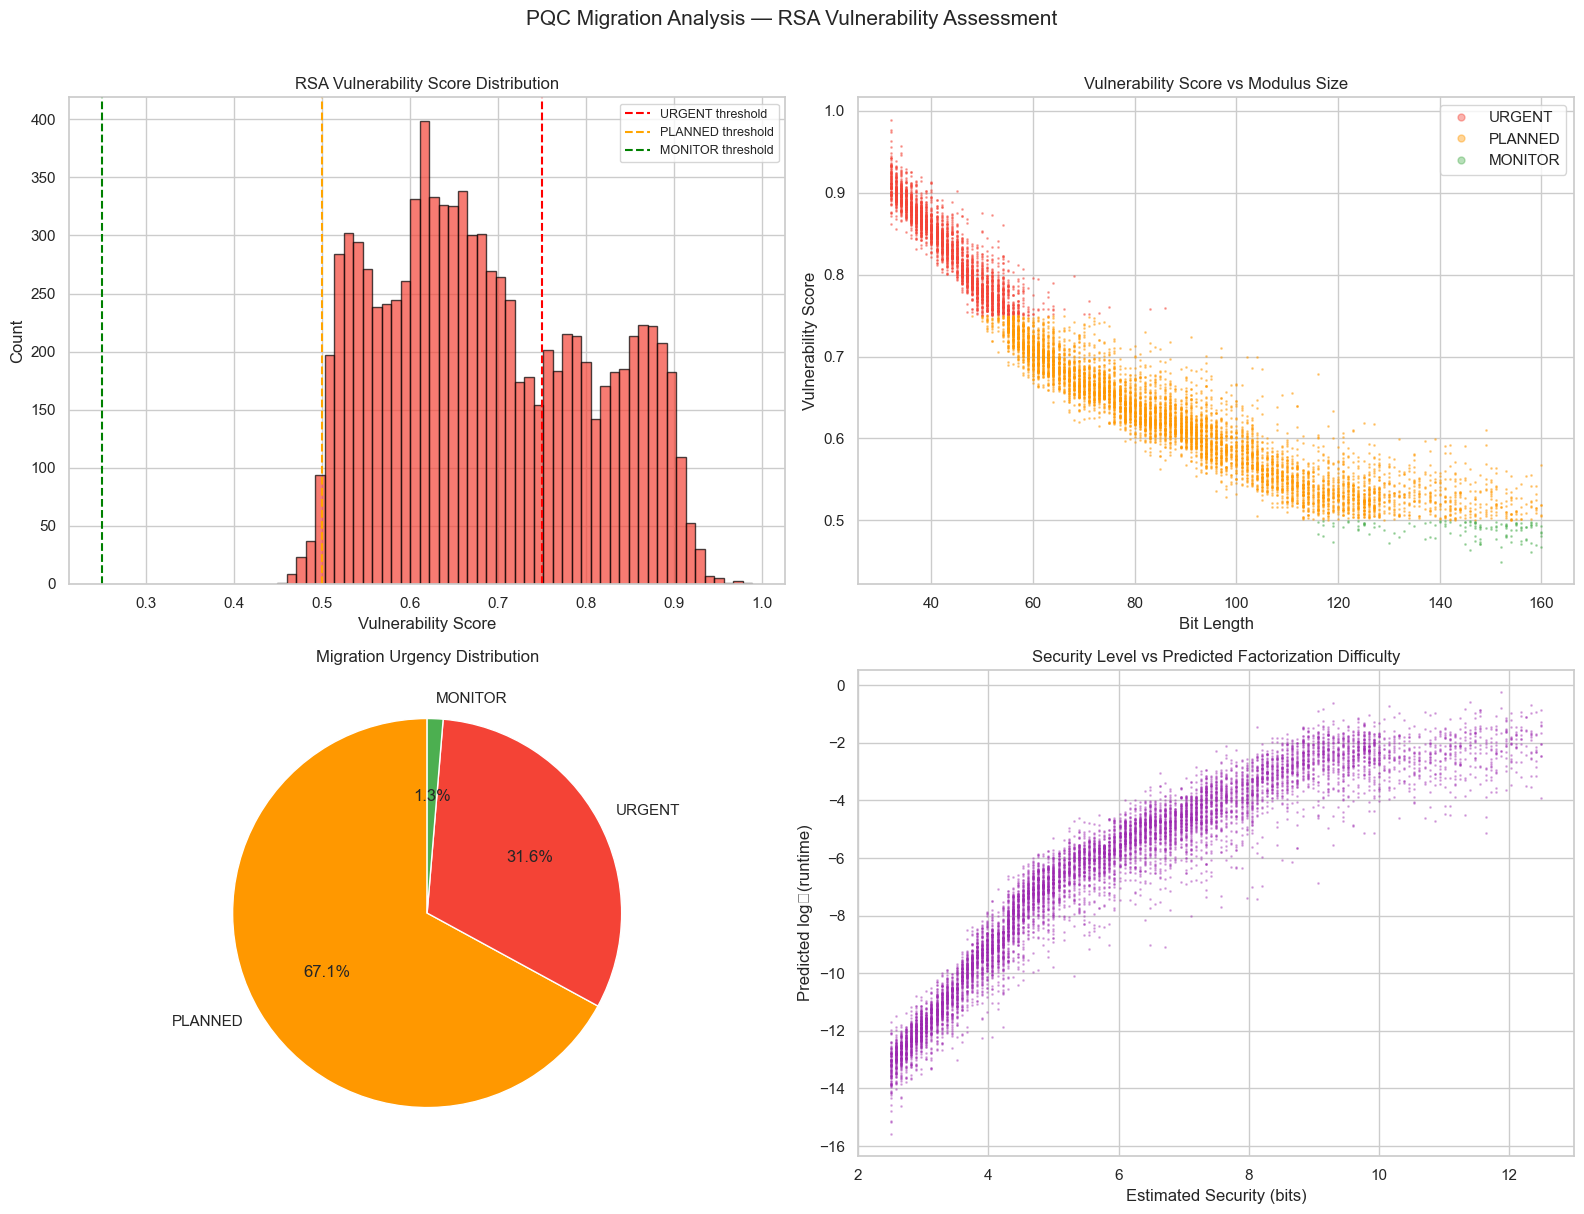

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures_pqc\01_pqc_migration_overview.png


In [5]:
print_section("PQC Migration Visualizations")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ─── Plot 1: Vulnerability score distribution ────────────
axes[0, 0].hist(df["vulnerability_score"].values, bins=50,
                edgecolor="black", alpha=0.7, color="#F44336")
axes[0, 0].set_xlabel("Vulnerability Score")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_title("RSA Vulnerability Score Distribution")
axes[0, 0].axvline(0.75, color="red", linestyle="--", linewidth=1.5, label="URGENT threshold")
axes[0, 0].axvline(0.50, color="orange", linestyle="--", linewidth=1.5, label="PLANNED threshold")
axes[0, 0].axvline(0.25, color="green", linestyle="--", linewidth=1.5, label="MONITOR threshold")
axes[0, 0].legend(fontsize=9)

# ─── Plot 2: Vulnerability vs bit-length ─────────────────
colors = {"URGENT": "#F44336", "PLANNED": "#FF9800", "MONITOR": "#4CAF50", "LOW RISK": "#2196F3"}
for tier in ["URGENT", "PLANNED", "MONITOR", "LOW RISK"]:
    subset = df[df["migration_tier"] == tier]
    if len(subset) > 0:
        axes[0, 1].plot(subset["bit_length"].values,
                        subset["vulnerability_score"].values,
                        ".", markersize=2, alpha=0.4,
                        color=colors[tier], label=tier)
axes[0, 1].set_xlabel("Bit Length")
axes[0, 1].set_ylabel("Vulnerability Score")
axes[0, 1].set_title("Vulnerability Score vs Modulus Size")
axes[0, 1].legend(markerscale=5)

# ─── Plot 3: Migration tier pie chart ────────────────────
tier_counts = df["migration_tier"].value_counts()
tier_colors = [colors.get(t, "gray") for t in tier_counts.index]
axes[1, 0].pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%',
               colors=tier_colors, startangle=90)
axes[1, 0].set_title("Migration Urgency Distribution")

# ─── Plot 4: Security bits vs predicted runtime ──────────
axes[1, 1].plot(df["estimated_security_bits"].values,
                df["predicted_log_runtime"].values,
                ".", markersize=2, alpha=0.3, color="#9C27B0")
axes[1, 1].set_xlabel("Estimated Security (bits)")
axes[1, 1].set_ylabel("Predicted log₂(runtime)")
axes[1, 1].set_title("Security Level vs Predicted Factorization Difficulty")

plt.suptitle("PQC Migration Analysis — RSA Vulnerability Assessment",
             fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(str(PQC_FIG / "01_pqc_migration_overview.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {PQC_FIG / '01_pqc_migration_overview.png'}")


══════════════════════════════════════════════════════════════════════
  Migration Heatmap
══════════════════════════════════════════════════════════════════════



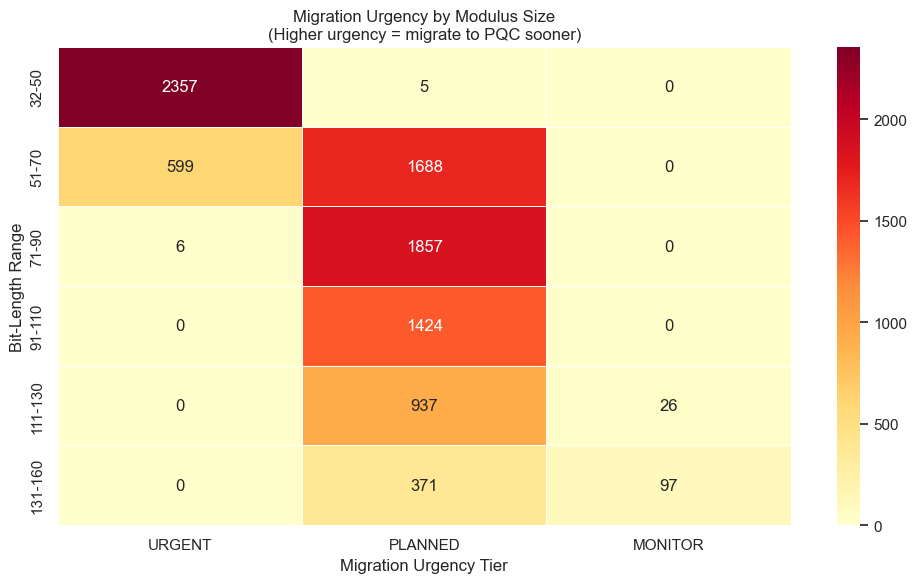

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures_pqc\02_migration_heatmap.png


In [6]:
# Migration recommendation heatmap: bit-length vs predicted algorithm
print_section("Migration Heatmap")

pivot = pd.crosstab(
    pd.cut(df["bit_length"], bins=[30, 50, 70, 90, 110, 130, 160],
           labels=["32-50", "51-70", "71-90", "91-110", "111-130", "131-160"]),
    df["migration_tier"],
)

# Reorder columns
col_order = ["URGENT", "PLANNED", "MONITOR", "LOW RISK"]
pivot = pivot[[c for c in col_order if c in pivot.columns]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_xlabel("Migration Urgency Tier")
ax.set_ylabel("Bit-Length Range")
ax.set_title("Migration Urgency by Modulus Size\n"
             "(Higher urgency = migrate to PQC sooner)")
plt.tight_layout()
plt.savefig(str(PQC_FIG / "02_migration_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {PQC_FIG / '02_migration_heatmap.png'}")

## 5. Save PQC Results & Phase Summary

In [7]:
print_section("Save PQC Results & Summary")

# ─── Save full PQC assessment table ──────────────────────
pqc_output_cols = [
    "N", "bit_length", "best_algorithm",
    "predicted_log_runtime", "predicted_algorithm",
    "estimated_security_bits", "pqc_level",
    "vulnerability_score", "migration_tier",
    "pqc_recommendation",
]
df[pqc_output_cols].to_csv(PQC_TAB / "pqc_migration_assessment.csv", index=False)
print(f"Assessment table: {PQC_TAB / 'pqc_migration_assessment.csv'}")

# ─── Save summary statistics ─────────────────────────────
tier_summary = df["migration_tier"].value_counts().to_dict()
algo_summary = df["predicted_algorithm"].value_counts().to_dict()

save_metadata(DATA_META / "pqc_migration_metadata.json", {
    "n_samples_assessed": len(df),
    "bit_range": [int(df["bit_length"].min()), int(df["bit_length"].max())],
    "vulnerability_score_range": [
        float(df["vulnerability_score"].min()),
        float(df["vulnerability_score"].max()),
    ],
    "migration_tier_distribution": tier_summary,
    "predicted_algorithm_distribution": algo_summary,
    "urgency_weights": URGENCY_WEIGHTS,
    "nist_reference": "NIST SP 800-57 Part 1 Rev. 5",
    "pqc_levels": {str(k): v for k, v in PQC_LEVELS.items()},
    "minimum_acceptable_security_bits": 112,
    "methodology": (
        "Vulnerability score = "
        f"{URGENCY_WEIGHTS['vulnerability']:.0%} predicted_ease + "
        f"{URGENCY_WEIGHTS['security_margin']:.0%} security_deficit + "
        f"{URGENCY_WEIGHTS['time_horizon']:.0%} time_horizon_factor"
    ),
})
print(f"Metadata: {DATA_META / 'pqc_migration_metadata.json'}")

# ─── Phase 4 Summary ─────────────────────────────────────
print(f"\n{'='*60}")
print(f"  PHASE 4 COMPLETE — PQC MIGRATION MODULE")
print(f"{'='*60}")

print(f"""
  METHODOLOGY:
  ─────────────────────────────────────────
  1. Predict factorization runtime (simplified ensemble)
  2. Predict best attack algorithm (4-class classifier)
  3. Estimate NIST security level (SP 800-57 interpolation)
  4. Compute vulnerability score (3-component weighted):
     - 50% predicted factorization ease
     - 30% security margin deficit
     - 20% quantum threat timeline factor
  5. Assign migration urgency tier

  RESULTS:
  ─────────────────────────────────────────
  Samples assessed:    {len(df):,}
  Bit range:           {int(df['bit_length'].min())}–{int(df['bit_length'].max())}""")

for tier in ["URGENT", "PLANNED", "MONITOR", "LOW RISK"]:
    count = tier_summary.get(tier, 0)
    pct = count / len(df) * 100
    print(f"  {tier:<20s}: {count:>5,} ({pct:.1f}%)")

print(f"""
  NOTE ON SCOPE:
  ─────────────────────────────────────────
  Our dataset uses 32–160 bit semiprimes (research scale).
  All fall below NIST Level 1 (< 128-bit security).
  In production (2048+ bit keys), the framework would
  produce a meaningful spread across Levels 1–5.

  The methodology is demonstrated and validated here.
  Scaling to production key sizes requires only:
  1. Extending the dataset to larger bit ranges
  2. Running the same feature extraction + prediction pipeline

  FILES SAVED:
  ─────────────────────────────────────────
  Assessment:   {PQC_TAB / 'pqc_migration_assessment.csv'}
  Metadata:     {DATA_META / 'pqc_migration_metadata.json'}
  Figures:      {PQC_FIG / '01_pqc_migration_overview.png'}
                {PQC_FIG / '02_migration_heatmap.png'}
""")

print(f"  → Phase 4 COMPLETE")
print(f"  → All computational phases done")
print(f"  → Ready for Phase 5: Paper Writing")

log_memory("phase 4 end")


══════════════════════════════════════════════════════════════════════
  Save PQC Results & Summary
══════════════════════════════════════════════════════════════════════

Assessment table: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_pqc\pqc_migration_assessment.csv
Metadata: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\meta\pqc_migration_metadata.json

  PHASE 4 COMPLETE — PQC MIGRATION MODULE

  METHODOLOGY:
  ─────────────────────────────────────────
  1. Predict factorization runtime (simplified ensemble)
  2. Predict best attack algorithm (4-class classifier)
  3. Estimate NIST security level (SP 800-57 interpolation)
  4. Compute vulnerability score (3-component weighted):
     - 50% predicted factorization ease
     - 30% security margin deficit
     - 20% quantum threat timeline factor
  5. Assign migration urgency tier

  RESULTS:
  ─────────────────────────────────────────
  Samples assessed